In [1]:
import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo

# 1. Download the dataset (id 336 = Chronic Kidney Disease)
ckd = fetch_ucirepo(id=336)
df = pd.concat([ckd.data.features, ckd.data.targets], axis=1)

# 2. Save an untouched copy of the original (in Colab's temporary storage)
df.to_csv("ckd_raw.csv", index=False)

# 3. First look
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nFirst 5 rows:")
print(df.head())
print("\nData types:")
print(df.dtypes)

# 4. Missing values per column
print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False))

# 5. Class balance (last column is the target)
target = df.columns[-1]
print("\nClass counts:")
print(df[target].value_counts(dropna=False))

# 6. Hidden mess in text columns (stray spaces, '?' and typos)
text_cols = df.select_dtypes(exclude="number").columns
for c in text_cols:
    print(c, "->", df[c].unique())

Shape: (400, 25)

Columns: ['age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'class']

First 5 rows:
    age    bp     sg   al   su     rbc        pc         pcc          ba  \
0  48.0  80.0  1.020  1.0  0.0     NaN    normal  notpresent  notpresent   
1   7.0  50.0  1.020  4.0  0.0     NaN    normal  notpresent  notpresent   
2  62.0  80.0  1.010  2.0  3.0  normal    normal  notpresent  notpresent   
3  48.0  70.0  1.005  4.0  0.0  normal  abnormal     present  notpresent   
4  51.0  80.0  1.010  2.0  0.0  normal    normal  notpresent  notpresent   

     bgr  ...   pcv    wbcc  rbcc  htn   dm  cad  appet   pe  ane class  
0  121.0  ...  44.0  7800.0   5.2  yes  yes   no   good   no   no   ckd  
1    NaN  ...  38.0  6000.0   NaN   no   no   no   good   no   no   ckd  
2  423.0  ...  31.0  7500.0   NaN   no  yes   no   poor   no  yes   ckd  
3  117.0  ...  32.0  6700.0   3.

In [2]:
df.describe()

,age,bp,sg,al,su,bgr,bu,sc,sod,pot,hemo,pcv,wbcc,rbcc
count,391.000000,388.000000,353.000000,354.000000,351.000000,356.000000,381.000000,383.000000,313.000000,312.000000,348.000000,329.000000,294.000000,269.000000
mean,51.483376,76.469072,1.017408,1.016949,0.450142,148.036517,57.425722,3.072454,137.528754,4.627244,12.526437,38.884498,8406.122449,4.707435
std,17.169714,13.683637,0.005717,1.352679,1.099191,79.281714,50.503006,5.741126,10.408752,3.193904,2.912587,8.990105,2944.474190,1.025323
min,2.000000,50.000000,1.005000,0.000000,0.000000,22.000000,1.500000,0.400000,4.500000,2.500000,3.100000,9.000000,2200.000000,2.100000
25%,42.000000,70.000000,1.010000,0.000000,0.000000,99.000000,27.000000,0.900000,135.000000,3.800000,10.300000,32.000000,6500.000000,3.900000
50%,55.000000,80.000000,1.020000,0.000000,0.000000,121.000000,42.000000,1.300000,138.000000,4.400000,12.650000,40.000000,8000.000000,4.800000
75%,64.500000,80.000000,1.020000,2.000000,0.000000,163.000000,66.000000,2.800000,142.000000,4.900000,15.000000,45.000000,9800.000000,5.400000
max,90.000000,180.000000,1.025000,5.000000,5.000000,490.000000,391.000000,76.000000,163.000000,47.000000,17.800000,54.000000,26400.000000,8.000000


In [4]:
# df.head()
df.tail()

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
395,55.0,80.0,1.020,0.0,0.0,normal,normal,notpresent,notpresent,140.0,...,47.0,6700.0,4.9,no,no,no,good,no,no,notckd
396,42.0,70.0,1.025,0.0,0.0,normal,normal,notpresent,notpresent,75.0,...,54.0,7800.0,6.2,no,no,no,good,no,no,notckd
397,12.0,80.0,1.020,0.0,0.0,normal,normal,notpresent,notpresent,100.0,...,49.0,6600.0,5.4,no,no,no,good,no,no,notckd
398,17.0,60.0,1.025,0.0,0.0,normal,normal,notpresent,notpresent,114.0,...,51.0,7200.0,5.9,no,no,no,good,no,no,notckd
399,58.0,80.0,1.025,0.0,0.0,normal,normal,notpresent,notpresent,131.0,...,53.0,6800.0,6.1,no,no,no,good,no,no,notckd


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

df = pd.read_csv("../data/raw/ckd_raw.csv")
print("Rows, columns:", df.shape)

Rows, columns: (400, 25)


In [7]:
df.to_csv("../data/raw/ckd_raw.csv", index=False)

In [8]:
numeric_cols = ["age", "bp", "bgr", "bu", "sc", "sod", "pot", "hemo", "pcv", "wbcc", "rbcc"]
level_cols = ["sg", "al", "su"]

binary_maps = {
    "rbc":   {"normal": 0, "abnormal": 1},
    "pc":    {"normal": 0, "abnormal": 1},
    "pcc":   {"notpresent": 0, "present": 1},
    "ba":    {"notpresent": 0, "present": 1},
    "htn":   {"no": 0, "yes": 1},
    "dm":    {"no": 0, "yes": 1},
    "cad":   {"no": 0, "yes": 1},
    "appet": {"good": 0, "poor": 1},
    "pe":    {"no": 0, "yes": 1},
    "ane":   {"no": 0, "yes": 1},
}
target_col = "class"

expected = set(numeric_cols) | set(level_cols) | set(binary_maps) | {target_col}
print("In the data but not in my lists:", set(df.columns) - expected)
print("In my lists but not in the data:", expected - set(df.columns))

In the data but not in my lists: set()
In my lists but not in the data: set()


In [10]:
def tidy_text(series):
    s = series.astype("string").str.strip().str.lower()
    return s.replace({"?": pd.NA, "": pd.NA})

clean = df.copy()
for c in clean.columns:
    clean[c] = tidy_text(clean[c])

print("Missing cells before tidy-up:", int(df.isna().sum().sum()))
print("Missing cells after tidy-up: ", int(clean.isna().sum().sum()))

Missing cells before tidy-up: 1012
Missing cells after tidy-up:  1012


In [11]:
for c in numeric_cols + level_cols:
    na_before = clean[c].isna().sum()
    clean[c] = pd.to_numeric(clean[c], errors="coerce")
    new_na = clean[c].isna().sum() - na_before
    if new_na:
        print(f"{c}: {new_na} value(s) could not be read as numbers and became missing")

In [12]:
for c, mapping in binary_maps.items():
    unexpected = set(clean[c].dropna().unique()) - set(mapping)
    if unexpected:
        print(f"{c}: unexpected values {unexpected}")
    clean[c] = pd.to_numeric(clean[c].map(mapping), errors="coerce")

In [13]:
print(clean[target_col].value_counts(dropna=False))

clean["ckd"] = clean[target_col].map({"ckd": 1, "notckd": 0})
assert clean["ckd"].notna().all(), "Some class labels were not recognised"
clean = clean.drop(columns=target_col)
clean["ckd"] = clean["ckd"].astype(int)

class
ckd       250
notckd    150
Name: count, dtype: int64[pyarrow]


       count     min      max
age    391.0     2.0     90.0
bp     388.0    50.0    180.0
sg     353.0   1.005    1.025
al     354.0     0.0      5.0
su     351.0     0.0      5.0
rbc    248.0     0.0      1.0
pc     335.0     0.0      1.0
pcc    396.0     0.0      1.0
ba     396.0     0.0      1.0
bgr    356.0    22.0    490.0
bu     381.0     1.5    391.0
sc     383.0     0.4     76.0
sod    313.0     4.5    163.0
pot    312.0     2.5     47.0
hemo   348.0     3.1     17.8
pcv    329.0     9.0     54.0
wbcc   294.0  2200.0  26400.0
rbcc   269.0     2.1      8.0
htn    398.0     0.0      1.0
dm     398.0     0.0      1.0
cad    398.0     0.0      1.0
appet  399.0     0.0      1.0
pe     399.0     0.0      1.0
ane    399.0     0.0      1.0
ckd    400.0     0.0      1.0
       missing  percent
rbc        152     38.0
rbcc       131     32.8
wbcc       106     26.5
pot         88     22.0
sod         87     21.8
pcv         71     17.8
pc          65     16.2
hemo        52     13.0
su  

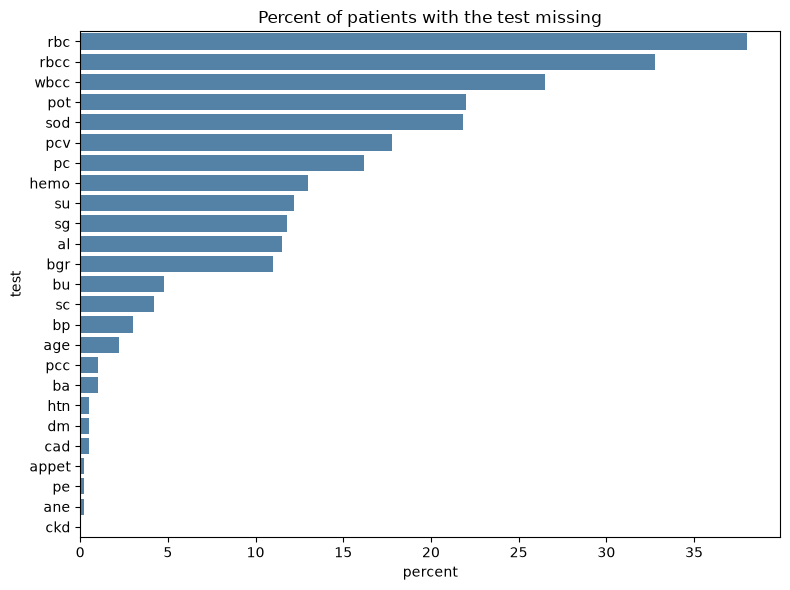

       % missing in healthy (0)  % missing in CKD (1)
pc                          6.0                  22.4
rbc                         6.0                  57.2
wbcc                        4.7                  39.6
rbcc                        4.7                  49.6
bu                          4.0                   5.2
bgr                         4.0                  15.2
hemo                        4.0                  18.4
al                          3.3                  16.4
sg                          3.3                  16.8
sod                         3.3                  32.8
pot                         3.3                  33.2
su                          3.3                  17.6
sc                          3.3                   4.8
pcv                         2.7                  26.8
pcc                         2.7                   0.0
ba                          2.7                   0.0
cad                         1.3                   0.0
bp                          

In [14]:
print(clean.describe().T[["count", "min", "max"]])

missing = clean.isna().sum().to_frame("missing")
missing["percent"] = (missing["missing"] / len(clean) * 100).round(1)
missing = missing.sort_values("missing", ascending=False)
print(missing[missing["missing"] > 0])

Path("../reports/figures").mkdir(parents=True, exist_ok=True)
plt.figure(figsize=(8, 6))
sns.barplot(data=missing.rename_axis("test").reset_index(), x="percent", y="test", color="steelblue")
plt.title("Percent of patients with the test missing")
plt.tight_layout()
plt.savefig("../reports/figures/missing_values.png", dpi=150)
plt.show()

by_class = clean.drop(columns="ckd").isna().groupby(clean["ckd"]).mean().T.mul(100).round(1)
by_class.columns = ["% missing in healthy (0)", "% missing in CKD (1)"]
print(by_class.sort_values("% missing in healthy (0)", ascending=False))

In [15]:
print("Duplicate rows:", clean.duplicated().sum())

Path("../data/processed").mkdir(parents=True, exist_ok=True)
clean.to_csv("../data/processed/ckd_clean.csv", index=False)
print("Saved:", clean.shape)

Duplicate rows: 0
Saved: (400, 25)


In [16]:
feature_cols = [c for c in clean.columns if c != "ckd"]

complete = clean.dropna()
print("Patients with every test recorded:", len(complete), "of", len(clean))
print(complete["ckd"].value_counts())

n_missing = clean[feature_cols].isna().sum(axis=1)
print(n_missing.groupby(clean["ckd"]).describe().round(1))

Patients with every test recorded: 158 of 400
ckd
0    115
1     43
Name: count, dtype: int64
     count  mean  std  min  25%  50%  75%   max
ckd                                            
0    150.0   0.7  1.4  0.0  0.0  0.0  0.0   6.0
1    250.0   3.6  3.0  0.0  1.0  3.0  5.0  11.0


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

flags = clean[feature_cols].isna().astype(int)
scores = cross_val_score(LogisticRegression(max_iter=1000), flags, clean["ckd"], cv=5)
print("Accuracy using ONLY which tests are blank:", scores.mean().round(3))
print("Accuracy of always guessing 'ckd':", round(clean["ckd"].mean(), 3))

Accuracy using ONLY which tests are blank: 0.81
Accuracy of always guessing 'ckd': 0.625


In [18]:
print(ckd)

{'data': {'ids': None, 'features':       age    bp     sg   al   su     rbc        pc         pcc          ba  \
0    48.0  80.0  1.020  1.0  0.0     NaN    normal  notpresent  notpresent   
1     7.0  50.0  1.020  4.0  0.0     NaN    normal  notpresent  notpresent   
2    62.0  80.0  1.010  2.0  3.0  normal    normal  notpresent  notpresent   
3    48.0  70.0  1.005  4.0  0.0  normal  abnormal     present  notpresent   
4    51.0  80.0  1.010  2.0  0.0  normal    normal  notpresent  notpresent   
..    ...   ...    ...  ...  ...     ...       ...         ...         ...   
395  55.0  80.0  1.020  0.0  0.0  normal    normal  notpresent  notpresent   
396  42.0  70.0  1.025  0.0  0.0  normal    normal  notpresent  notpresent   
397  12.0  80.0  1.020  0.0  0.0  normal    normal  notpresent  notpresent   
398  17.0  60.0  1.025  0.0  0.0  normal    normal  notpresent  notpresent   
399  58.0  80.0  1.025  0.0  0.0  normal    normal  notpresent  notpresent   

       bgr  ...  hemo   pcv 

In [20]:
df.describe()

,age,bp,sg,al,su,bgr,bu,sc,sod,pot,hemo,pcv,wbcc,rbcc
count,391.000000,388.000000,353.000000,354.000000,351.000000,356.000000,381.000000,383.000000,313.000000,312.000000,348.000000,329.000000,294.000000,269.000000
mean,51.483376,76.469072,1.017408,1.016949,0.450142,148.036517,57.425722,3.072454,137.528754,4.627244,12.526437,38.884498,8406.122449,4.707435
std,17.169714,13.683637,0.005717,1.352679,1.099191,79.281714,50.503006,5.741126,10.408752,3.193904,2.912587,8.990105,2944.474190,1.025323
min,2.000000,50.000000,1.005000,0.000000,0.000000,22.000000,1.500000,0.400000,4.500000,2.500000,3.100000,9.000000,2200.000000,2.100000
25%,42.000000,70.000000,1.010000,0.000000,0.000000,99.000000,27.000000,0.900000,135.000000,3.800000,10.300000,32.000000,6500.000000,3.900000
50%,55.000000,80.000000,1.020000,0.000000,0.000000,121.000000,42.000000,1.300000,138.000000,4.400000,12.650000,40.000000,8000.000000,4.800000
75%,64.500000,80.000000,1.020000,2.000000,0.000000,163.000000,66.000000,2.800000,142.000000,4.900000,15.000000,45.000000,9800.000000,5.400000
max,90.000000,180.000000,1.025000,5.000000,5.000000,490.000000,391.000000,76.000000,163.000000,47.000000,17.800000,54.000000,26400.000000,8.000000


In [21]:
print(complete)

      age    bp     sg   al   su  rbc   pc  pcc   ba    bgr  ...   pcv  \
3    48.0  70.0  1.005  4.0  0.0  0.0  1.0  1.0  0.0  117.0  ...  32.0   
9    53.0  90.0   1.02  2.0  0.0  1.0  1.0  1.0  0.0   70.0  ...  29.0   
11   63.0  70.0   1.01  3.0  0.0  1.0  1.0  1.0  0.0  380.0  ...  32.0   
14   68.0  80.0   1.01  3.0  2.0  0.0  1.0  1.0  1.0  157.0  ...  16.0   
20   61.0  80.0  1.015  2.0  0.0  1.0  1.0  0.0  0.0  173.0  ...  24.0   
..    ...   ...    ...  ...  ...  ...  ...  ...  ...    ...  ...   ...   
395  55.0  80.0   1.02  0.0  0.0  0.0  0.0  0.0  0.0  140.0  ...  47.0   
396  42.0  70.0  1.025  0.0  0.0  0.0  0.0  0.0  0.0   75.0  ...  54.0   
397  12.0  80.0   1.02  0.0  0.0  0.0  0.0  0.0  0.0  100.0  ...  49.0   
398  17.0  60.0  1.025  0.0  0.0  0.0  0.0  0.0  0.0  114.0  ...  51.0   
399  58.0  80.0  1.025  0.0  0.0  0.0  0.0  0.0  0.0  131.0  ...  53.0   

        wbcc  rbcc  htn   dm  cad  appet   pe  ane  ckd  
3     6700.0   3.9  1.0  0.0  0.0    1.0  1.0  1.0   

In [22]:
print(clean)

      age    bp     sg   al   su   rbc   pc  pcc   ba    bgr  ...   pcv  \
0    48.0  80.0   1.02  1.0  0.0  <NA>  0.0  0.0  0.0  121.0  ...  44.0   
1     7.0  50.0   1.02  4.0  0.0  <NA>  0.0  0.0  0.0   <NA>  ...  38.0   
2    62.0  80.0   1.01  2.0  3.0   0.0  0.0  0.0  0.0  423.0  ...  31.0   
3    48.0  70.0  1.005  4.0  0.0   0.0  1.0  1.0  0.0  117.0  ...  32.0   
4    51.0  80.0   1.01  2.0  0.0   0.0  0.0  0.0  0.0  106.0  ...  35.0   
..    ...   ...    ...  ...  ...   ...  ...  ...  ...    ...  ...   ...   
395  55.0  80.0   1.02  0.0  0.0   0.0  0.0  0.0  0.0  140.0  ...  47.0   
396  42.0  70.0  1.025  0.0  0.0   0.0  0.0  0.0  0.0   75.0  ...  54.0   
397  12.0  80.0   1.02  0.0  0.0   0.0  0.0  0.0  0.0  100.0  ...  49.0   
398  17.0  60.0  1.025  0.0  0.0   0.0  0.0  0.0  0.0  114.0  ...  51.0   
399  58.0  80.0  1.025  0.0  0.0   0.0  0.0  0.0  0.0  131.0  ...  53.0   

       wbcc  rbcc  htn   dm  cad  appet   pe  ane  ckd  
0    7800.0   5.2  1.0  1.0  0.0    0.0  0